In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
!wget -nc https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

File ‘course_lead_scoring_2026.csv’ already there; not retrieving.



Data preparation

In [3]:
df = pd.read_csv('course_lead_scoring_2026.csv')

In [4]:
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [6]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [7]:
categorical = [
    'lead_source',
    'industry',
    'employment_status',
    'location'
]

In [8]:
numerical = [
    'annual_income',
    'number_of_courses_viewed',
    'interaction_count',
    'lead_score'
]

In [9]:
for c in categorical:
    df[c] = df[c].fillna('NA')

In [10]:
for n in numerical:
    df[n] = df[n].fillna(0.0)

In [11]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

Split the data into 3 parts with these exact calls:

In [12]:
df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [13]:
df_train.shape, df_val.shape, df_test.shape

((3000, 9), (1000, 9), (1000, 9))

In [14]:
y_train = df_train['converted'].values

Question 1: ROC AUC feature importance

In [15]:
for n in numerical:
    auc = roc_auc_score(y_train, df_train[n])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[n])

    print(n, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


The numerical variable that has the highest AUC is lead_score.



Question 2: Training the model

In [16]:
dicts = df[categorical + numerical].to_dict(orient='records')

In [17]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [18]:
X_train.shape

(3000, 28)

In [19]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [20]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
)

model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [21]:
y_val = df_val['converted'].values

In [22]:
y_pred = model.predict_proba(X_val)[:, 1]

In [23]:
round(roc_auc_score(y_val, y_pred),3)

0.732

The AUC of this model on the validation dataset, round to 3 digits, is 0.732.


Question 3: Precision and Recall

In [24]:
scores = []

thresholds = np.arange(0, 1.01, 0.01)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    p = tp / (tp + fp) if (tp + fp) > 0 else 0    
    r = tp / (tp + fn) if (tp + fn) > 0 else 0

    scores.append((t, tp, fp, fn, tn, p, r))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn', 'p', 'r']
df_scores = pd.DataFrame(scores, columns=columns)


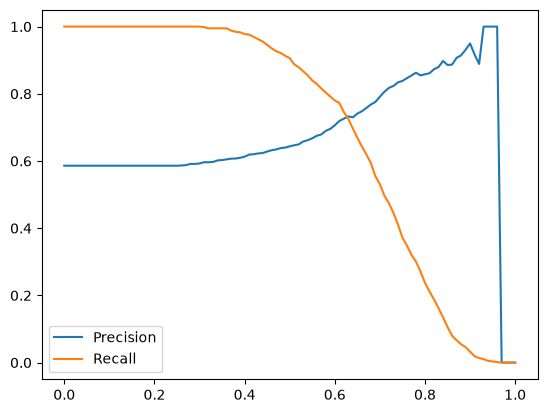

In [25]:
plt.plot(df_scores.threshold, df_scores['p'], label='Precision')
plt.plot(df_scores.threshold, df_scores['r'], label='Recall')
plt.legend()

In [26]:

df_scores['difference'] = abs(df_scores['p'] - df_scores['r'])

valid_scores = df_scores[
    (df_scores['p'] != 0) | (df_scores['r'] != 0)
]

idx = valid_scores['difference'].idxmin()

In [27]:
valid_scores.loc[idx, 'threshold']


np.float64(0.63)

In [28]:
valid_scores.loc[idx, ['threshold', 'p', 'r', 'difference']]

threshold     0.630000
p             0.732759
r             0.725256
difference    0.007503
Name: 63, dtype: float64

At threshold = 0.63 precision and recall curves intersect.


Question 4: F1 score

In [29]:
df_scores['f1'] = (2 * df_scores['p']  * (df_scores['r'] ))/ (df_scores['p'] + (df_scores['r']))

In [30]:
idxmax = df_scores['f1'].idxmax()
df_scores.loc[idxmax, ['threshold', 'p', 'r', 'f1']]


threshold    0.410000
p            0.619048
r            0.976109
f1           0.757616
Name: 41, dtype: float64

At threshold = 0.41 F1 is maximal.



Question 5: 5-Fold CV

In [31]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]
    y_train_fold = df_train_fold['converted'].values
    y_val_fold = df_val_fold['converted'].values
    
    train_dict = df_train_fold[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train_fold = dv.fit_transform(train_dict)
    
    val_dict = df_val_fold[categorical + numerical].to_dict(orient='records')
    X_val_fold = dv.transform(val_dict)

    model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000
    )

    model.fit(X_train_fold, y_train_fold)

    y_pred_fold = model.predict_proba(X_val_fold)[:, 1]

    auc = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc)

print('Mean AUC:', np.mean(scores))
print('Std AUC:', np.std(scores))

Mean AUC: 0.7317269710972524
Std AUC: 0.006853233151022138


In [32]:
scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

Standard deviation of the scores across different folds is 0.006853233151022138 = 0.007


Question 6: Hyperparameter Tuning

In [33]:
C_values = [0.000001, 0.001, 1]

for C in C_values:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_fold = df_full_train.iloc[train_idx]
        df_val_fold = df_full_train.iloc[val_idx]
        y_train_fold = df_train_fold['converted'].values
        y_val_fold = df_val_fold['converted'].values
    
        train_dict = df_train_fold[categorical + numerical].to_dict(orient='records')
        dv = DictVectorizer(sparse=False)
        X_train_fold = dv.fit_transform(train_dict)
        val_dict = df_val_fold[categorical + numerical].to_dict(orient='records')
        X_val_fold = dv.transform(val_dict)

        model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000
        )

        model.fit(X_train_fold, y_train_fold)

        y_pred_fold = model.predict_proba(X_val_fold)[:, 1]

        auc = roc_auc_score(y_val_fold, y_pred_fold)
        scores.append(auc)
  
    print(C, round(np.mean(scores), 3), round(np.std(scores), 3))

1e-06 0.617 0.019
0.001 0.749 0.01
1 0.732 0.007


C = 0.001 leads to the best mean ROC AUC (0.749).
